# Eros Carvalho — Projeto Integrador

**Arquivos utilizados:** `BALANCO_ENERGIA_SUBSISTEMA_2023.csv`  `BALANCO_ENERGIA_SUBSISTEMA_2024.csv`  `BALANCO_ENERGIA_SUBSISTEMA_2025.csv`  
**Pergunta:** Como a carga e a composição da geração local influenciam a condição importadora ou exportadora dos subsistemas do SIN, e como o ONS pode sinalizar períodos preferenciais onde os agentes podem concentrar suas manutenções na rede? 
**Dados:** DADOS DO BALANÇO DE ENERGIA NOS SUBSISTEMAS · **Unidade:** MWmed · **Licença:** CC BY



## 1. Ambiente e bibliotecas


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from matplotlib.ticker import FuncFormatter
pd.options.display.float_format = '{:.2f}'.format

PASTA_SAIDA = Path.cwd() / "Saidas"
PASTA_SAIDA.mkdir(exist_ok=True)

print(PASTA_SAIDA)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)


/home/devkit/Curso/Projeto/Saidas
Python: 3.14.4
pandas: 3.0.5


## 2. Carregamento Base


In [2]:
Arquivos = [
    Path.cwd() / "Base"/ "BALANCO_ENERGIA_SUBSISTEMA_2023.csv",
    Path.cwd() / "Base"/ "BALANCO_ENERGIA_SUBSISTEMA_2024.csv",
    Path.cwd() / "Base"/ "BALANCO_ENERGIA_SUBSISTEMA_2025.csv",
]
for arquivo in Arquivos:
    if arquivo.exists():
        df = pd.read_csv(arquivo, sep=";")
        print(f"Arquivo: {arquivo.name}")
        print(f"Dimensão: {df.shape}")
        print("-" * 50)
    else:
        print(f"Arquivo não encontrado: {arquivo.name}")

Arquivo: BALANCO_ENERGIA_SUBSISTEMA_2023.csv
Dimensão: (43800, 9)
--------------------------------------------------
Arquivo: BALANCO_ENERGIA_SUBSISTEMA_2024.csv
Dimensão: (43920, 9)
--------------------------------------------------
Arquivo: BALANCO_ENERGIA_SUBSISTEMA_2025.csv
Dimensão: (43800, 9)
--------------------------------------------------


## 3. Inspeção dos Dados


In [3]:
for arquivo in Arquivos:
    print("\n" + "="*50)
    print(f"Arquivo: {arquivo.name}")

    df = pd.read_csv(arquivo, sep=";")

    print(f"Dimensão: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
    print("\nColunas:")
    print(df.columns.tolist())

    print("\nPrimeiras linhas:")
    display(df.head(4))

    print("\nÚltimas linhas:")
    display(df.tail(4))

    print("\nAmostra aleatória:")
    display(df.sample(min(4, len(df)), random_state=42))


Arquivo: BALANCO_ENERGIA_SUBSISTEMA_2023.csv
Dimensão: 43,800 linhas x 9 colunas

Colunas:
['id_subsistema', 'nom_subsistema', 'din_instante', 'val_gerhidraulica', 'val_gertermica', 'val_gereolica', 'val_gersolar', 'val_carga', 'val_intercambio']

Primeiras linhas:


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
0,NE,NORDESTE,2023-01-01 00:00:00,3874.07,677.06,13305.26,1.93,10455.82,7402.51
1,N,NORTE,2023-01-01 00:00:00,7858.74,877.85,211.77,0.00,5990.55,2957.82
2,SIN,SISTEMA INTERLIGADO NACIONAL,2023-01-01 00:00:00,39057.31,5698.34,14138.75,21.16,58904.08,11.47
3,SE,SUDESTE/CENTRO-OESTE,2023-01-01 00:00:00,24661.11,4071.58,6.00,18.22,32183.88,-3426.97



Últimas linhas:


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
43796,N,NORTE,2023-12-31 23:00:00,3334.50,2430.85,3.43,0.00,6641.41,-872.63
43797,SIN,SISTEMA INTERLIGADO NACIONAL,2023-12-31 23:00:00,52629.36,8982.85,3588.31,11.24,65212.05,-0.29
43798,SE,SUDESTE/CENTRO-OESTE,2023-12-31 23:00:00,32794.01,5073.43,8.50,8.69,36060.08,1824.56
43799,S,SUL,2023-12-31 23:00:00,13067.82,994.45,622.16,1.00,10365.65,4319.78



Amostra aleatória:


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
28101,N,NORTE,2023-08-23 04:00:00,3325.47,1414.92,370.07,0.00,7480.71,-2370.26
25482,SIN,SISTEMA INTERLIGADO NACIONAL,2023-08-01 08:00:00,36596.35,9174.13,15645.00,12730.14,74145.63,0.00
19891,N,NORTE,2023-06-15 18:00:00,11792.80,2598.58,315.93,4.86,7009.00,7703.17
43029,S,SUL,2023-12-25 13:00:00,6515.87,908.87,338.64,2435.12,10085.15,113.34


... (8 outputs left out)


Últimas linhas:


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
43796,N,NORTE,2025-12-31 23:00:00,11435.86,1860.17,299.41,0.00,7739.27,5856.17
43797,SIN,SISTEMA INTERLIGADO NACIONAL,2025-12-31 23:00:00,54541.99,8267.27,11872.45,1.00,74682.71,0.00
43798,SE,SUDESTE/CENTRO-OESTE,2025-12-31 23:00:00,27730.87,5679.69,187.18,0.00,42418.29,-8820.55
43799,S,SUL,2025-12-31 23:00:00,11883.13,158.42,587.18,1.00,11458.17,1171.56



Amostra aleatória:


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
28101,N,NORTE,2025-08-23 04:00:00,2515.50,2945.15,417.72,0.00,8488.25,-2609.88
25482,SIN,SISTEMA INTERLIGADO NACIONAL,2025-08-01 08:00:00,29794.46,13981.44,15839.78,19135.35,77036.01,1715.01
19891,N,NORTE,2025-06-15 18:00:00,11238.99,1849.04,319.55,14.55,7706.24,5715.89
43029,S,SUL,2025-12-25 13:00:00,3996.25,232.87,47.84,3604.88,10451.98,-2570.13


In [4]:
hora_ano = (7*31+4*30+28)*24
hora_ano_bissexto = (7*31+4*30+29)*24
print("horas no ano =", hora_ano)
print("horas no ano bissexto=", hora_ano_bissexto)

for arquivo in Arquivos:
    print("\n" + "="*50)
    print(f"Arquivo: {arquivo.name}")

    df = pd.read_csv(arquivo, sep=";")
    print("\n" + "="*50)
    print(f"Arquivo: {arquivo.name}")
    df.info()
    display(df.dtypes.rename("tipo_lido"))
    display(df.describe(include="all").T)

horas no ano = 8760
horas no ano bissexto= 8784

Arquivo: BALANCO_ENERGIA_SUBSISTEMA_2023.csv

Arquivo: BALANCO_ENERGIA_SUBSISTEMA_2023.csv
<class 'pandas.DataFrame'>
RangeIndex: 43800 entries, 0 to 43799
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_subsistema      43800 non-null  str    
 1   nom_subsistema     43800 non-null  str    
 2   din_instante       43800 non-null  str    
 3   val_gerhidraulica  43800 non-null  float64
 4   val_gertermica     43800 non-null  float64
 5   val_gereolica      43800 non-null  float64
 6   val_gersolar       43800 non-null  float64
 7   val_carga          43800 non-null  float64
 8   val_intercambio    43800 non-null  float64
dtypes: float64(6), str(3)
memory usage: 4.4 MB


id_subsistema            str
nom_subsistema           str
din_instante             str
val_gerhidraulica    float64
val_gertermica       float64
val_gereolica        float64
val_gersolar         float64
val_carga            float64
val_intercambio      float64
Name: tipo_lido, dtype: object

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_subsistema,43800,5,NE,8760,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nom_subsistema,43800,5,NORDESTE,8760,NaN,NaN,NaN,NaN,NaN,NaN,NaN
din_instante,43800,8760,2023-01-01 00:00:00,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
val_gerhidraulica,43800.00,NaN,NaN,NaN,20186.74,18586.55,275.27,4623.82,12964.62,32613.47,81006.77
val_gertermica,43800.00,NaN,NaN,NaN,3300.19,3172.90,64.60,842.75,1455.86,6057.10,19248.15
val_gereolica,43800.00,NaN,NaN,NaN,4355.14,5559.51,0.00,78.81,574.32,9277.00,20166.24
val_gersolar,43800.00,NaN,NaN,NaN,1963.89,4002.36,0.00,1.00,16.72,2098.32,27222.57
val_carga,43800.00,NaN,NaN,NaN,29482.00,25817.64,1364.25,10083.59,13622.21,46238.04,101472.17
val_intercambio,43800.00,NaN,NaN,NaN,323.97,4750.77,-13021.59,-2930.09,63.20,3345.39,14146.51



Arquivo: BALANCO_ENERGIA_SUBSISTEMA_2024.csv

Arquivo: BALANCO_ENERGIA_SUBSISTEMA_2024.csv
<class 'pandas.DataFrame'>
RangeIndex: 43920 entries, 0 to 43919
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_subsistema      43920 non-null  str    
 1   nom_subsistema     43920 non-null  str    
 2   din_instante       43920 non-null  str    
 3   val_gerhidraulica  43920 non-null  float64
 4   val_gertermica     43920 non-null  float64
 5   val_gereolica      43920 non-null  float64
 6   val_gersolar       43920 non-null  float64
 7   val_carga          43920 non-null  float64
 8   val_intercambio    43920 non-null  float64
dtypes: float64(6), str(3)
memory usage: 4.4 MB


id_subsistema            str
nom_subsistema           str
din_instante             str
val_gerhidraulica    float64
val_gertermica       float64
val_gereolica        float64
val_gersolar         float64
val_carga            float64
val_intercambio      float64
Name: tipo_lido, dtype: object

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_subsistema,43920,5,NE,8784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nom_subsistema,43920,5,NORDESTE,8784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
din_instante,43920,8784,2024-01-01 00:00:00,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
val_gerhidraulica,43920.00,NaN,NaN,NaN,19504.46,18163.26,1456.24,4591.51,12861.05,31064.11,87875.71
val_gertermica,43920.00,NaN,NaN,NaN,3907.49,3955.41,116.25,926.80,1951.46,6569.91,19869.30
val_gereolica,43920.00,NaN,NaN,NaN,4895.17,6439.67,0.00,64.71,668.00,10063.43,23698.72
val_gersolar,43920.00,NaN,NaN,NaN,3339.86,6032.46,0.00,1.46,159.16,3999.83,36016.02
val_carga,43920.00,NaN,NaN,NaN,31577.30,27481.13,5816.49,11020.63,14553.56,49203.58,102086.33
val_intercambio,43920.00,NaN,NaN,NaN,69.68,5127.73,-16172.03,-2389.35,0.00,2437.83,13101.96



Arquivo: BALANCO_ENERGIA_SUBSISTEMA_2025.csv

Arquivo: BALANCO_ENERGIA_SUBSISTEMA_2025.csv
<class 'pandas.DataFrame'>
RangeIndex: 43800 entries, 0 to 43799
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_subsistema      43800 non-null  str    
 1   nom_subsistema     43800 non-null  str    
 2   din_instante       43800 non-null  str    
 3   val_gerhidraulica  43800 non-null  float64
 4   val_gertermica     43800 non-null  float64
 5   val_gereolica      43800 non-null  float64
 6   val_gersolar       43800 non-null  float64
 7   val_carga          43800 non-null  float64
 8   val_intercambio    43800 non-null  float64
dtypes: float64(6), str(3)
memory usage: 4.4 MB


id_subsistema            str
nom_subsistema           str
din_instante             str
val_gerhidraulica    float64
val_gertermica       float64
val_gereolica        float64
val_gersolar         float64
val_carga            float64
val_intercambio      float64
Name: tipo_lido, dtype: object

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_subsistema,43800,5,NE,8760,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nom_subsistema,43800,5,NORDESTE,8760,NaN,NaN,NaN,NaN,NaN,NaN,NaN
din_instante,43800,8760,2025-01-01 00:00:00,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
val_gerhidraulica,43800.00,NaN,NaN,NaN,18440.11,17904.11,814.22,3864.64,11405.37,29657.61,85895.76
val_gertermica,43800.00,NaN,NaN,NaN,4081.35,4018.26,19.00,981.22,2455.16,6562.03,16795.30
val_gereolica,43800.00,NaN,NaN,NaN,5267.64,6957.62,0.00,153.85,604.66,10501.16,25064.76
val_gersolar,43800.00,NaN,NaN,NaN,4193.27,7510.63,0.00,0.28,215.49,4958.80,42551.69
val_carga,43800.00,NaN,NaN,NaN,31843.56,27591.84,6015.88,11083.30,14760.82,48845.60,106148.66
val_intercambio,43800.00,NaN,NaN,NaN,138.81,5250.27,-13840.64,-3320.15,0.00,2668.83,13591.51


## 4. Preparação, Consolidação e validação


In [5]:

linhas = 0
colunas = 0

for arquivo in Arquivos:
    df = pd.read_csv(arquivo, sep=";")

    linhas += df.shape[0]
    colunas = df.shape[1]

print(f"Total de linhas: {linhas}")
print(f"Soma das colunas: {colunas}")

dfs = []

for arquivo in Arquivos:

    df = pd.read_csv(arquivo, sep=";")

    dfs.append(df)

dados = pd.concat(dfs, ignore_index=True)

print("Dimensão consolidada:")
print(dados.shape)

display(dados.head())

display(
    dados.groupby("id_subsistema")
         .size()
         .rename("registros")
         .to_frame()
)

dados = pd.concat(dfs, ignore_index=True)
dados = dados.rename(columns={
    "id_subsistema": "cod_sub",
    "nom_subsistema": "subsistema",
    "din_instante": "data_hora",
    "val_carga": "carga",
    "val_gerhidraulica": "UHE",
    "val_gertermica": "UTE",
    "val_gereolica": "EOL",
    "val_gersolar": "UFV",
    "val_intercambio": "intercambio",
}).copy()


dados["data_hora"] = pd.to_datetime(dados["data_hora"])
dados["ano"] = dados["data_hora"].dt.year
dados["mes"] = dados["data_hora"].dt.month
dados["hora"] = dados["data_hora"].dt.hour
dados["dia"] = dados["data_hora"].dt.day
dados["dia_semana"] = dados["data_hora"].dt.day_name()

dados["tipo_dia"] = np.where(
    dados["data_hora"].dt.dayofweek < 5,
    "Dia Útil",
    "Dia Não Útil"
)
dados["tipo_dia"].value_counts()
print("Anos encontrados:")
print(sorted(dados["ano"].unique()))

print("\nQuantidade por ano:")
display(dados["ano"].value_counts().sort_index())

dados["geracao_total"] = (
    dados["UHE"]
    + dados["UTE"]
    + dados["EOL"]
    + dados["UFV"]
)

dados["saldo_energia"] = (
    dados["geracao_total"]
    - dados["carga"]
)

dados["condicao"] = np.where(
    dados["intercambio"] >= 0,
    "Exportador",
    "Importador"
)

display(dados.head())
display(dados.isna().sum())
print("Duplicatas:", dados.duplicated(["data_hora", "cod_sub"]).sum())
display(dados["subsistema"].value_counts())
print("Período:", dados["data_hora"].min().date(), "a", dados["data_hora"].max().date())

print("Dados faltantes por variável")
display(
    dados.isna()
         .sum()
         .rename("Valores Faltantes")
         .to_frame()
)
print("Validações concluídas.")

Total de linhas: 131520
Soma das colunas: 9
Dimensão consolidada:
(131520, 9)


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
0,NE,NORDESTE,2023-01-01 00:00:00,3874.07,677.06,13305.26,1.93,10455.82,7402.51
1,N,NORTE,2023-01-01 00:00:00,7858.74,877.85,211.77,0.00,5990.55,2957.82
2,SIN,SISTEMA INTERLIGADO NACIONAL,2023-01-01 00:00:00,39057.31,5698.34,14138.75,21.16,58904.08,11.47
3,SE,SUDESTE/CENTRO-OESTE,2023-01-01 00:00:00,24661.11,4071.58,6.00,18.22,32183.88,-3426.97
4,S,SUL,2023-01-01 00:00:00,2663.38,71.84,615.72,1.00,10273.83,-6921.89


,registros
id_subsistema,
N,26304
NE,26304
S,26304
SE,26304
SIN,26304


Anos encontrados:
[np.int32(2023), np.int32(2024), np.int32(2025)]

Quantidade por ano:


ano
2023    43800
2024    43920
2025    43800
Name: count, dtype: int64

,cod_sub,subsistema,data_hora,UHE,UTE,EOL,UFV,carga,intercambio,ano,mes,hora,dia,dia_semana,tipo_dia,geracao_total,saldo_energia,condicao
0,NE,NORDESTE,2023-01-01,3874.07,677.06,13305.26,1.93,10455.82,7402.51,2023,1,0,1,Sunday,Dia Não Útil,17858.33,7402.51,Exportador
1,N,NORTE,2023-01-01,7858.74,877.85,211.77,0.00,5990.55,2957.82,2023,1,0,1,Sunday,Dia Não Útil,8948.37,2957.82,Exportador
2,SIN,SISTEMA INTERLIGADO NACIONAL,2023-01-01,39057.31,5698.34,14138.75,21.16,58904.08,11.47,2023,1,0,1,Sunday,Dia Não Útil,58915.55,11.47,Exportador
3,SE,SUDESTE/CENTRO-OESTE,2023-01-01,24661.11,4071.58,6.00,18.22,32183.88,-3426.97,2023,1,0,1,Sunday,Dia Não Útil,28756.91,-3426.97,Importador
4,S,SUL,2023-01-01,2663.38,71.84,615.72,1.00,10273.83,-6921.89,2023,1,0,1,Sunday,Dia Não Útil,3351.94,-6921.89,Importador


... (2 outputs left out)

subsistema
NORDESTE                        26304
NORTE                           26304
SISTEMA INTERLIGADO NACIONAL    26304
SUDESTE/CENTRO-OESTE            26304
SUL                             26304
Name: count, dtype: int64

Período: 2023-01-01 a 2025-12-31
Dados faltantes por variável


,Valores Faltantes
cod_sub,0
subsistema,0
data_hora,0
UHE,0
UTE,0
EOL,0
UFV,0
carga,0
intercambio,0
ano,0


Validações concluídas.


## 5. Fechamento do Balanço


In [6]:
TOLERANCIA = 1e-1  # MWmed

dados["fechamento"] = (
    dados["UHE"]
    + dados["UTE"]
    + dados["EOL"]
    + dados["UFV"]
    - dados["intercambio"]
    - dados["carga"]
)

erros = dados[dados["fechamento"].abs() > TOLERANCIA]

print(f"Registros analisados: {len(dados):,}")
print(f"Registros com diferença: {len(erros):,}")

if len(erros) > 0:
    display(
        erros[
            [
                "data_hora",
                "nom_subsistema",
                "fechamento",
            ]
        ].head(20)
    )
else:
    print("Todos os registros fecharam o balanço.")

Registros analisados: 131,520
Registros com diferença: 0
Todos os registros fecharam o balanço.


## 6. Menores e maiores demandas do SIN


In [7]:
for arquivo in Arquivos:

    print("\n" + "=" * 50)
    print(f"Arquivo: {arquivo.name}")

    df = pd.read_csv(arquivo, sep=";")
    df_sin = df[df["id_subsistema"] == "SIN"]
    #sin = dados.query("id_subsistema == 'SIN'")
    display(df_sin.nsmallest(5, "val_carga")[["din_instante", "id_subsistema", "val_carga"]])
    display(df_sin.nlargest(5, "val_carga")[["din_instante", "id_subsistema", "val_carga"]])


Arquivo: BALANCO_ENERGIA_SUBSISTEMA_2023.csv


,din_instante,id_subsistema,val_carga
47,2023-01-01 09:00:00,SIN,46389.75
52,2023-01-01 10:00:00,SIN,46693.10
42,2023-01-01 08:00:00,SIN,47220.14
57,2023-01-01 11:00:00,SIN,47458.12
62,2023-01-01 12:00:00,SIN,47740.86


,din_instante,id_subsistema,val_carga
38112,2023-11-14 14:00:00,SIN,101472.17
38472,2023-11-17 14:00:00,SIN,101048.63
38357,2023-11-16 15:00:00,SIN,101021.67
37992,2023-11-13 14:00:00,SIN,100865.47
38352,2023-11-16 14:00:00,SIN,100631.52



Arquivo: BALANCO_ENERGIA_SUBSISTEMA_2024.csv


,din_instante,id_subsistema,val_carga
18392,2024-06-02 06:00:00,SIN,55450.23
18397,2024-06-02 07:00:00,SIN,55626.44
18387,2024-06-02 05:00:00,SIN,55958.68
18382,2024-06-02 04:00:00,SIN,56158.76
26792,2024-08-11 06:00:00,SIN,56296.20


,din_instante,id_subsistema,val_carga
8952,2024-03-15 14:00:00,SIN,102086.33
8837,2024-03-14 15:00:00,SIN,101508.27
4512,2024-02-07 14:00:00,SIN,101477.51
8957,2024-03-15 15:00:00,SIN,101358.72
39912,2024-11-28 14:00:00,SIN,101245.44



Arquivo: BALANCO_ENERGIA_SUBSISTEMA_2025.csv


,din_instante,id_subsistema,val_carga
26592,2025-08-10 14:00:00,SIN,55129.83
22357,2025-07-06 07:00:00,SIN,55764.64
22352,2025-07-06 06:00:00,SIN,55952.68
26597,2025-08-10 15:00:00,SIN,56073.36
22347,2025-07-06 05:00:00,SIN,56337.08


,din_instante,id_subsistema,val_carga
6792,2025-02-26 14:00:00,SIN,106148.66
6672,2025-02-25 14:00:00,SIN,105314.79
6677,2025-02-25 15:00:00,SIN,105184.59
6787,2025-02-26 13:00:00,SIN,105152.44
6552,2025-02-24 14:00:00,SIN,105123.00


## 7. Estatísticas gerais dos subsistemas

In [8]:
resumo_subsistema = (
    dados
    .query("cod_sub != 'SIN'")
    .groupby("subsistema")
    .agg(
        carga_media=("carga","mean"),
        carga_max=("carga","max"),
        carga_min=("carga","min"),
        intercambio_medio=("intercambio","mean")
    )
    .round(2)
)

display(resumo_subsistema)
resumo_subsistema.to_csv(
    PASTA_SAIDA / "01_estatisticas_gerais_subsistemas.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig"
)

,carga_media,carga_max,carga_min,intercambio_medio
subsistema,,,,
NORDESTE,12835.40,18156.97,7262.28,5259.09
NORTE,7757.26,10239.23,1364.25,2172.61
SUDESTE/CENTRO-OESTE,43521.53,62149.88,26260.22,-5821.45
SUL,13306.25,22737.44,6439.20,-1166.78


## 8. Evolução da carga ao longo do tempo


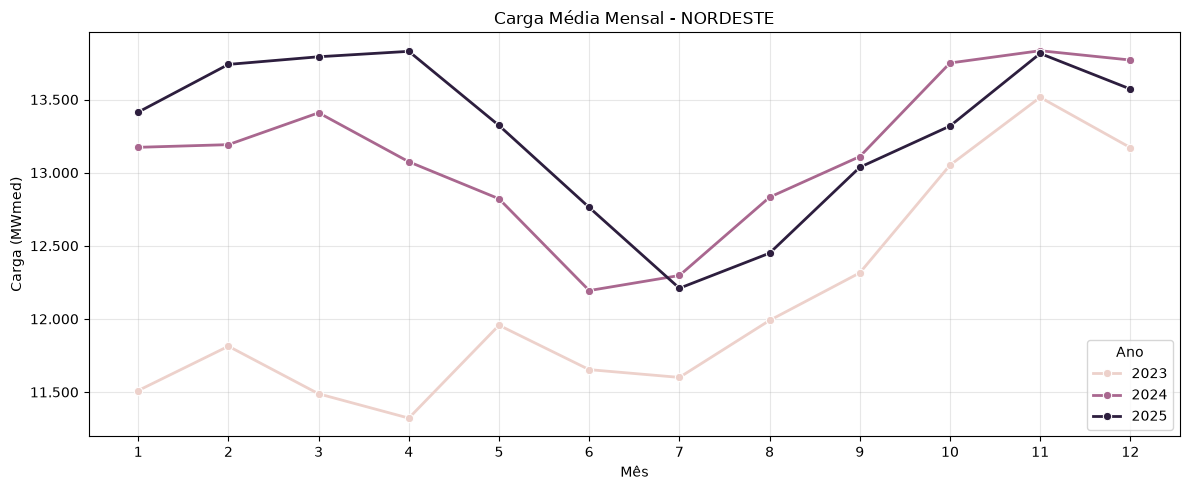

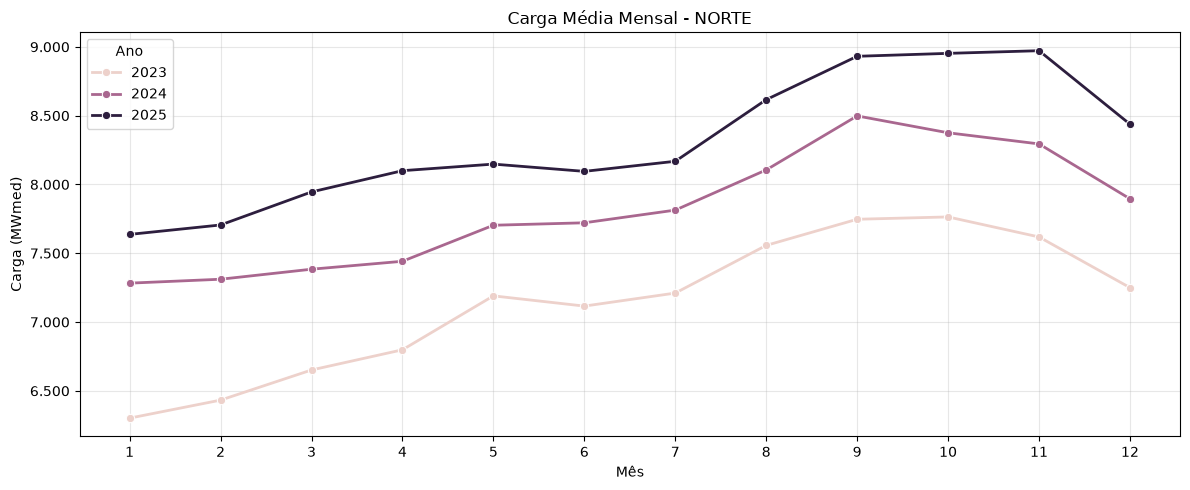

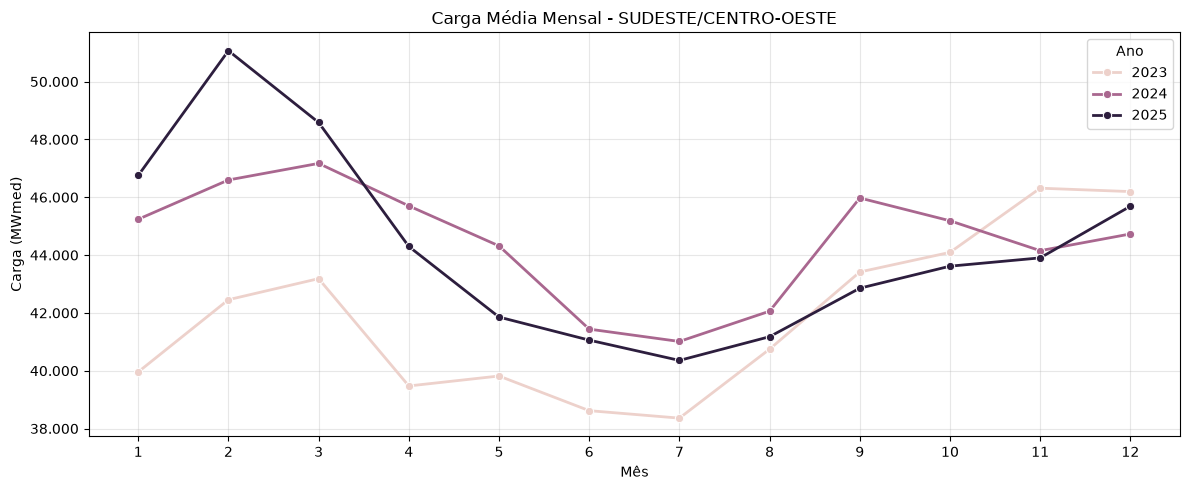

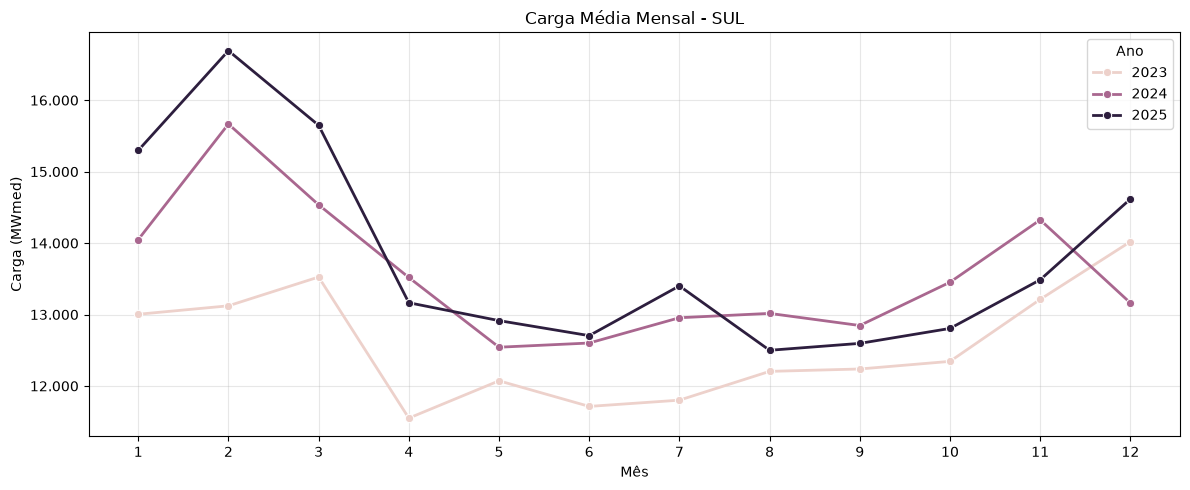

In [9]:
carga_mensal = (
    dados
    .query("cod_sub != 'SIN'")
    .groupby(["ano", "mes", "subsistema"])
    ["carga"]
    .mean()
    .reset_index()
)

for sub in carga_mensal["subsistema"].unique():

    plt.figure(figsize=(12,5))

    dados_sub = carga_mensal[
        carga_mensal["subsistema"] == sub
    ]

    sns.lineplot(
        data=dados_sub,
        x="mes",
        y="carga",
        hue="ano",
        marker="o",
        linewidth=2
    )

    ax = plt.gca()

    ax.yaxis.set_major_formatter(
        FuncFormatter(
            lambda x, p:
            f"{x:,.0f}".replace(",", ".")
        )
    )

    plt.title(
        f"Carga Média Mensal - {sub}"
    )

    plt.xlabel("Mês")
    plt.ylabel("Carga (MWmed)")

    plt.xticks(range(1,13))

    plt.grid(alpha=0.3)

    plt.legend(title="Ano")

    plt.tight_layout()
    nome_sub = (
        sub
        .replace("/", "_")
        .replace(" ", "_")
    )
    plt.savefig(
        PASTA_SAIDA / f"Carga_Mensal_{nome_sub}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## 9. Perfil horário da carga

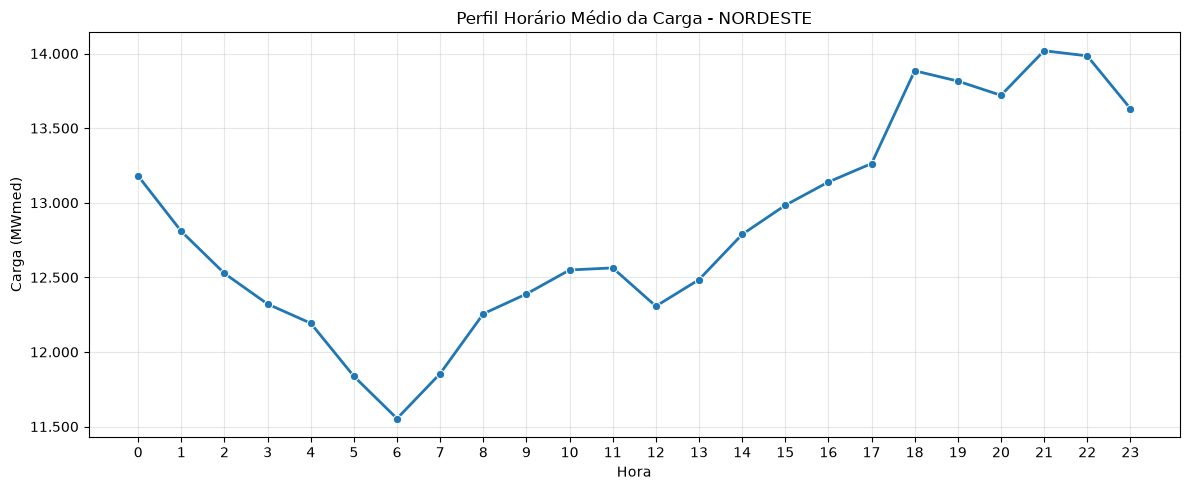

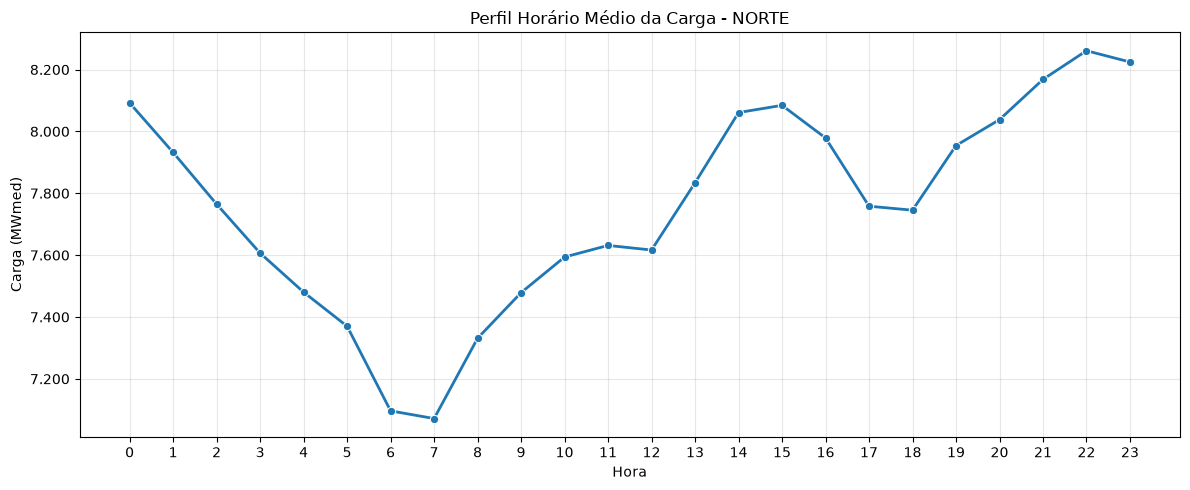

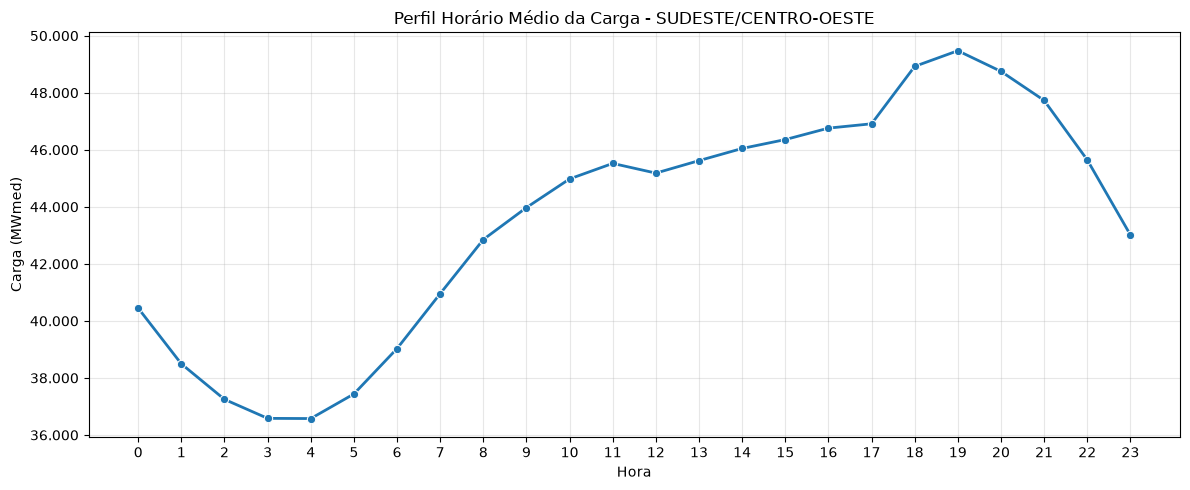

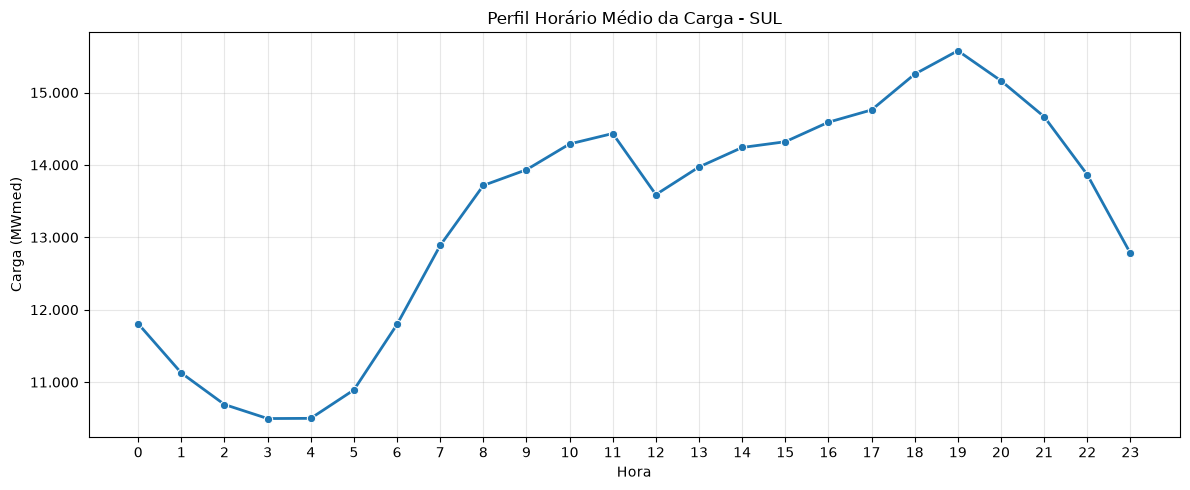

In [10]:
perfil_horario = (
    dados
    .query("cod_sub != 'SIN'")
    .groupby(
        ["hora", "subsistema"]
    )["carga"]
    .mean()
    .reset_index()
)

for sub in perfil_horario["subsistema"].unique():

    plt.figure(figsize=(12,5))

    dados_sub = perfil_horario[
        perfil_horario["subsistema"] == sub
    ]

    sns.lineplot(
        data=dados_sub,
        x="hora",
        y="carga",
        marker="o",
        linewidth=2
    )

    ax = plt.gca()

    ax.yaxis.set_major_formatter(
        FuncFormatter(
            lambda x, p:
            f"{x:,.0f}".replace(",", ".")
        )
    )

    plt.title(
        f"Perfil Horário Médio da Carga - {sub}"
    )

    plt.xlabel("Hora")
    plt.ylabel("Carga (MWmed)")

    plt.xticks(range(0,24))

    plt.grid(alpha=0.3)

    plt.tight_layout()

    nome_sub = (
        sub
        .replace("/", "_")
        .replace(" ", "_")
    )
    plt.savefig(
        PASTA_SAIDA / f"Perfil_horario_{nome_sub}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## 9.A Perfil de carga por mês

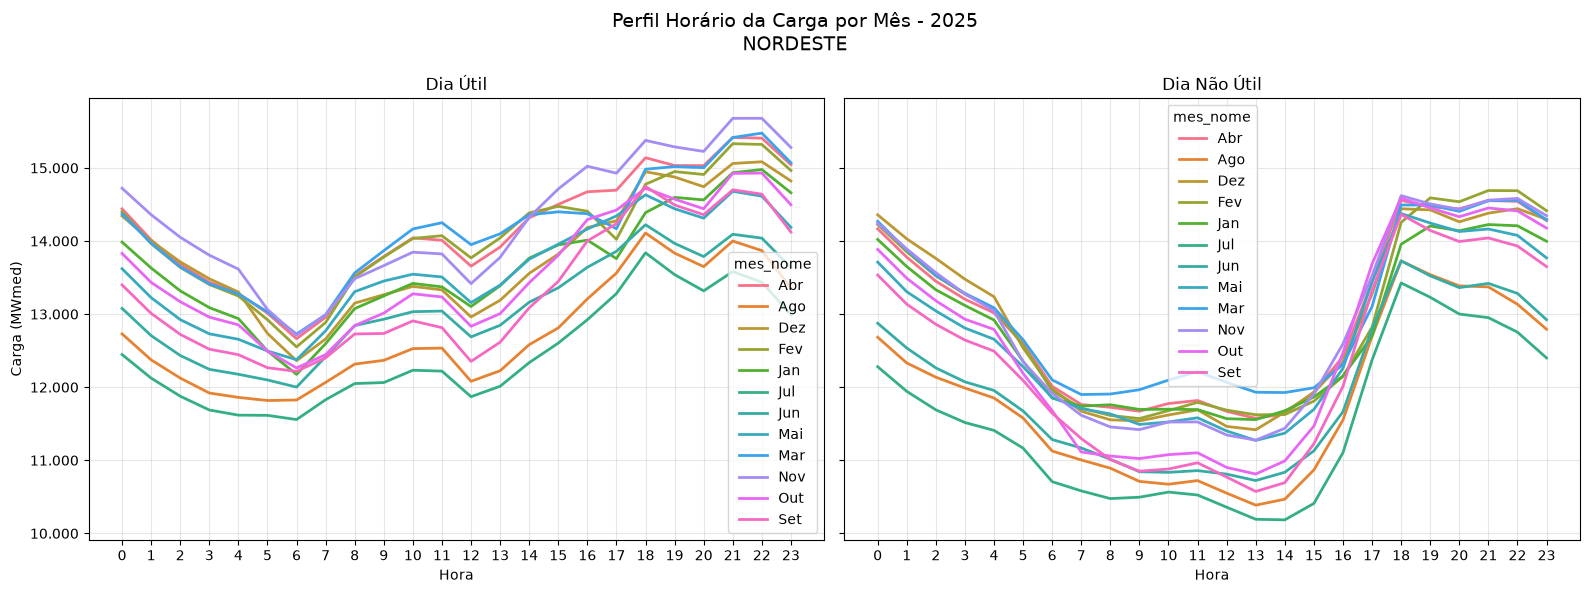

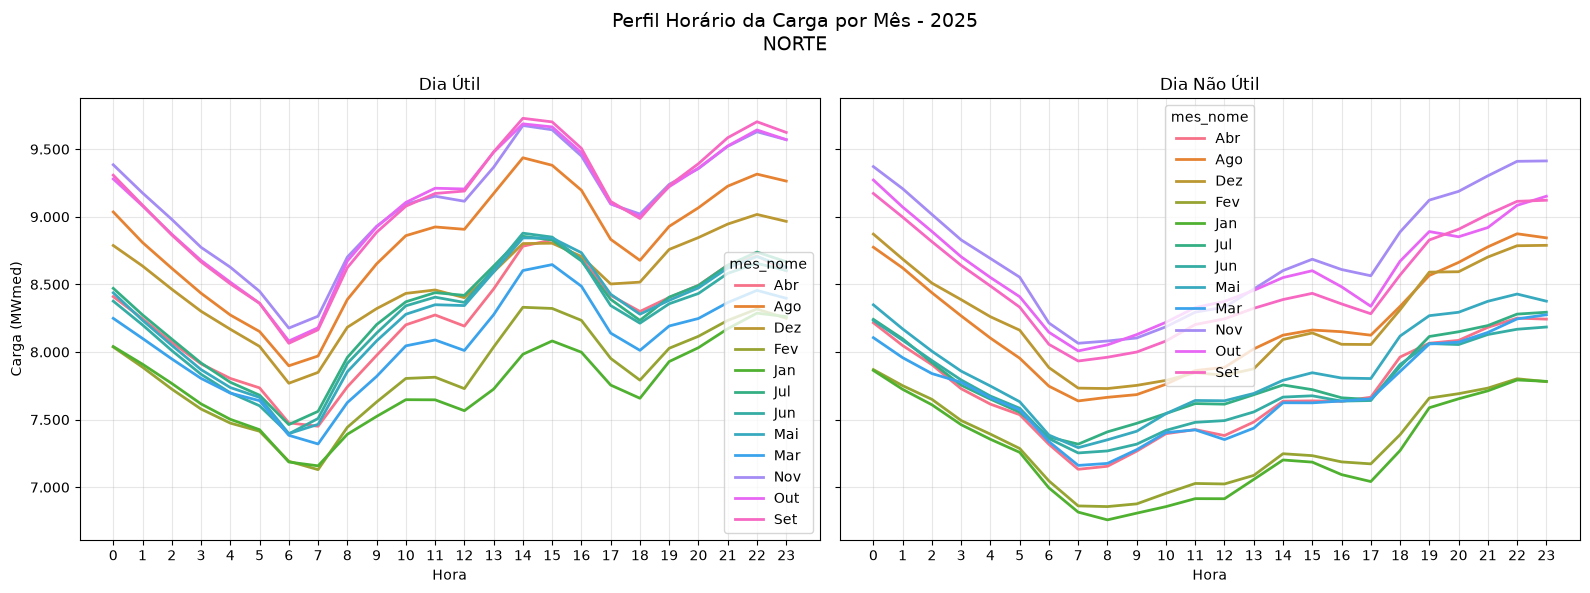

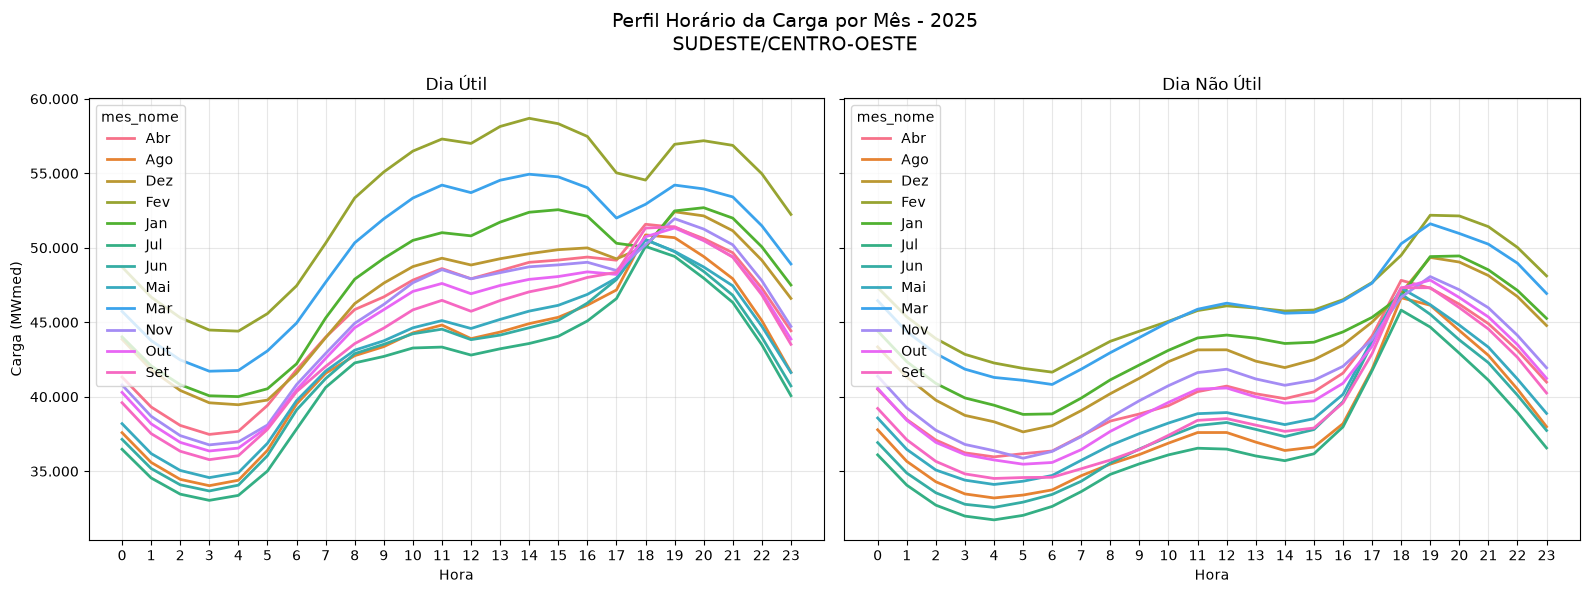

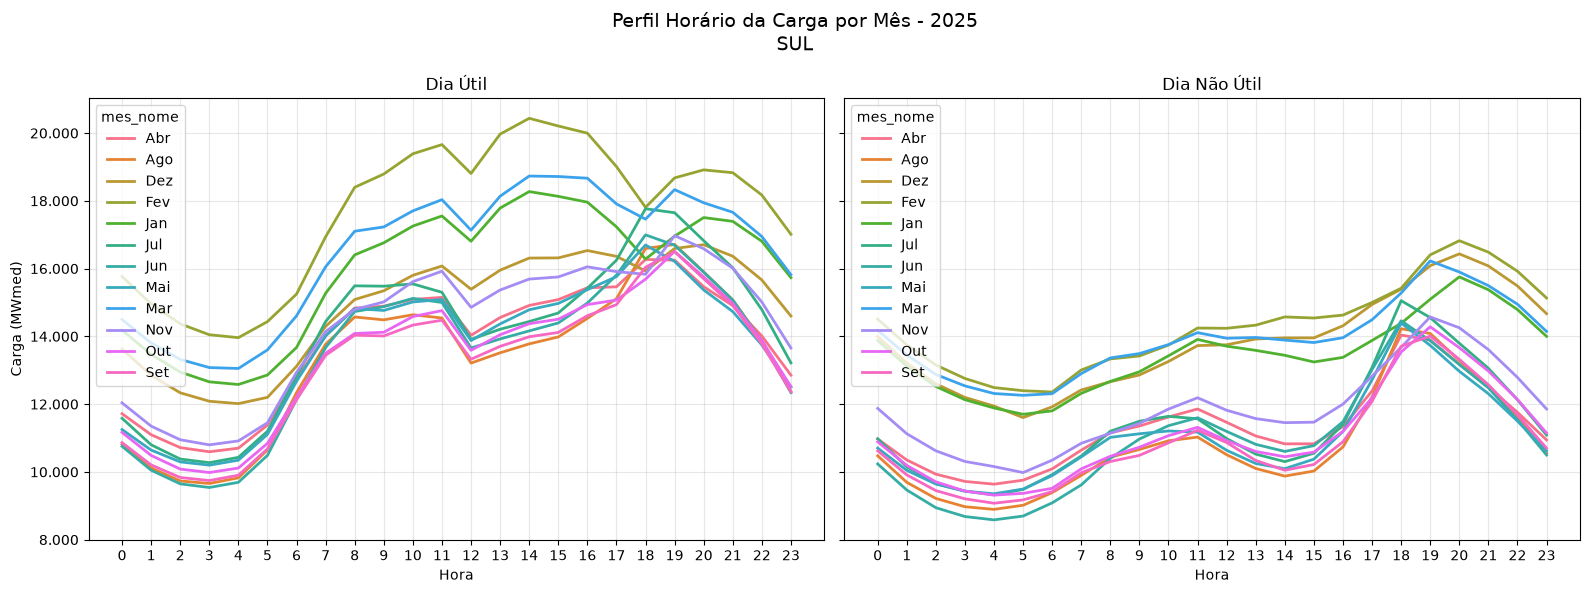

In [11]:
dados_2025 = dados.query(
    "ano == 2025 and cod_sub != 'SIN'"
).copy()

mapa_mes = {
    1:"Jan",
    2:"Fev",
    3:"Mar",
    4:"Abr",
    5:"Mai",
    6:"Jun",
    7:"Jul",
    8:"Ago",
    9:"Set",
    10:"Out",
    11:"Nov",
    12:"Dez"
}

dados_2025["mes_nome"] = (
    dados_2025["mes"].map(mapa_mes)
)

perfil_mes = (
    dados_2025
    .groupby(
        [
            "subsistema",
            "tipo_dia",
            "mes_nome",
            "hora"
        ]
    )["carga"]
    .mean()
    .reset_index()
)

for sub in perfil_mes["subsistema"].unique():

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16,6),
        sharey=True
    )

    for i, tipo in enumerate(
        ["Dia Útil", "Dia Não Útil"]
    ):

        dados_plot = perfil_mes[
            (perfil_mes["subsistema"] == sub)
            &
            (perfil_mes["tipo_dia"] == tipo)
        ]

        sns.lineplot(
            data=dados_plot,
            x="hora",
            y="carga",
            hue="mes_nome",
            linewidth=2,
            ax=axes[i]
        )

        axes[i].set_title(tipo)

        axes[i].set_xlabel("Hora")

        axes[i].set_ylabel("Carga (MWmed)")

        axes[i].set_xticks(range(24))

        axes[i].grid(alpha=0.3)

        axes[i].yaxis.set_major_formatter(
            FuncFormatter(
                lambda x, p:
                f"{x:,.0f}".replace(",", ".")
            )
        )

    fig.suptitle(
        f"Perfil Horário da Carga por Mês - 2025\n{sub}",
        fontsize=14
    )

    plt.tight_layout()

    nome_sub = (
            sub
            .replace("/", "_")
            .replace(" ", "_")
        )
    plt.savefig(
       PASTA_SAIDA / f"Perfil_Mes_{nome_sub}.png",
       dpi=300,
       bbox_inches="tight"
    )

    plt.show()

## 9.B Perfil de carga por estação do ano

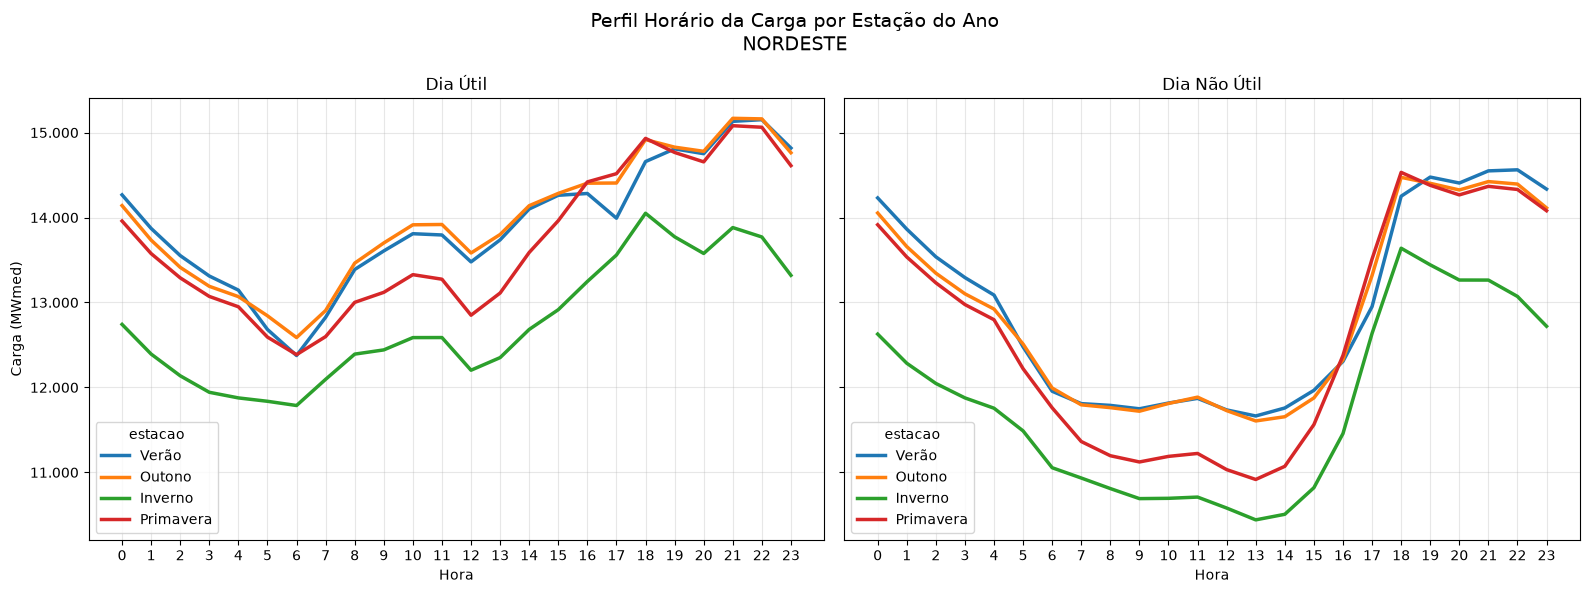

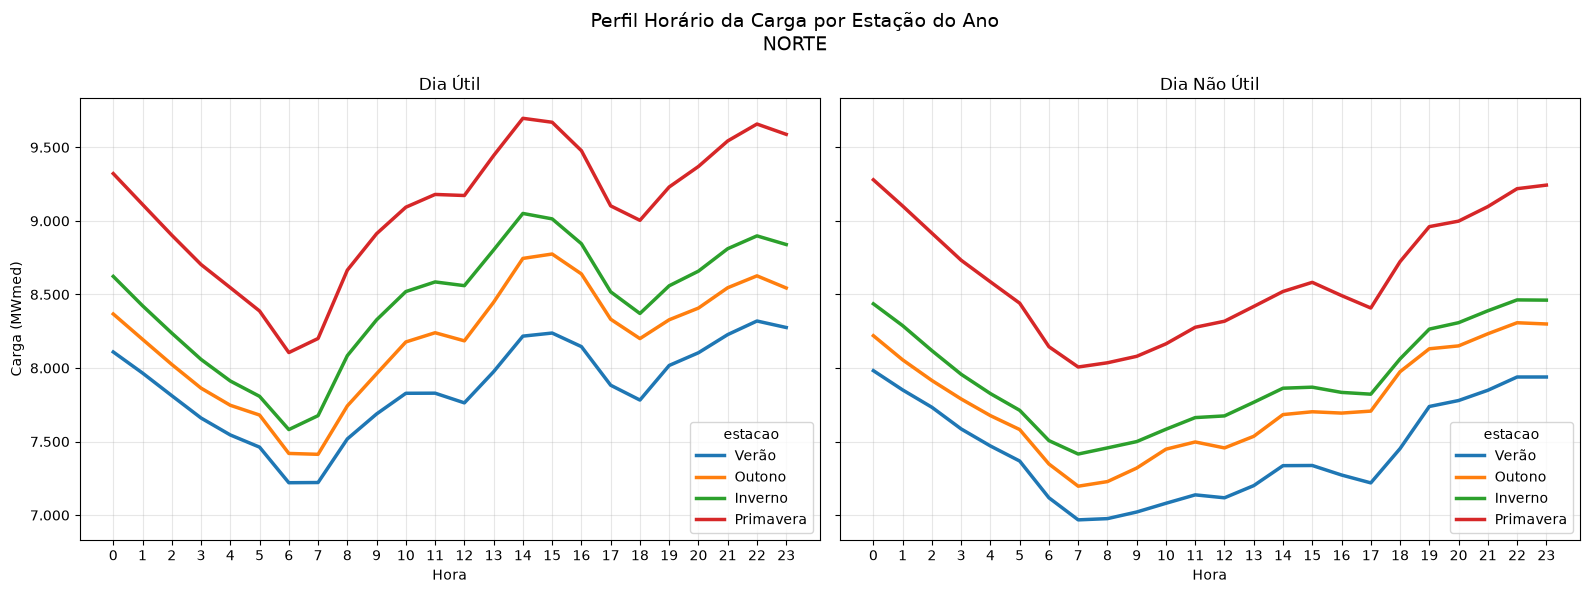

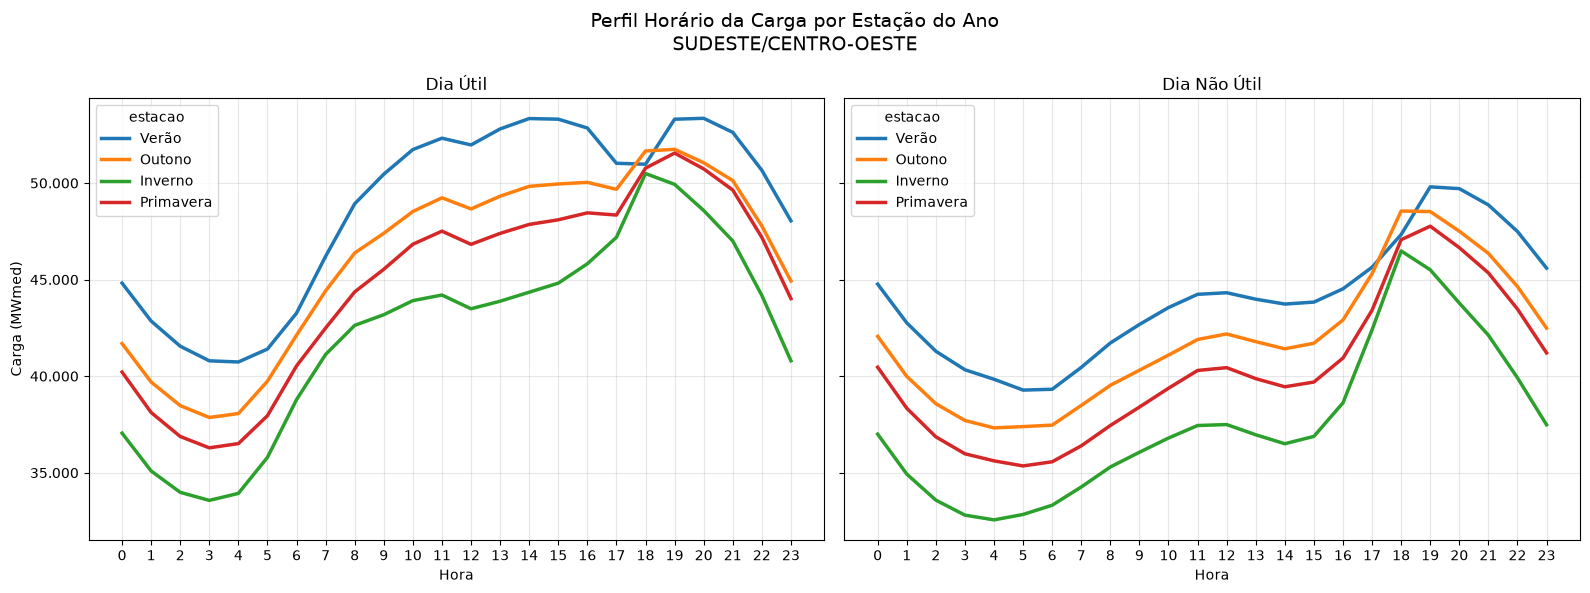

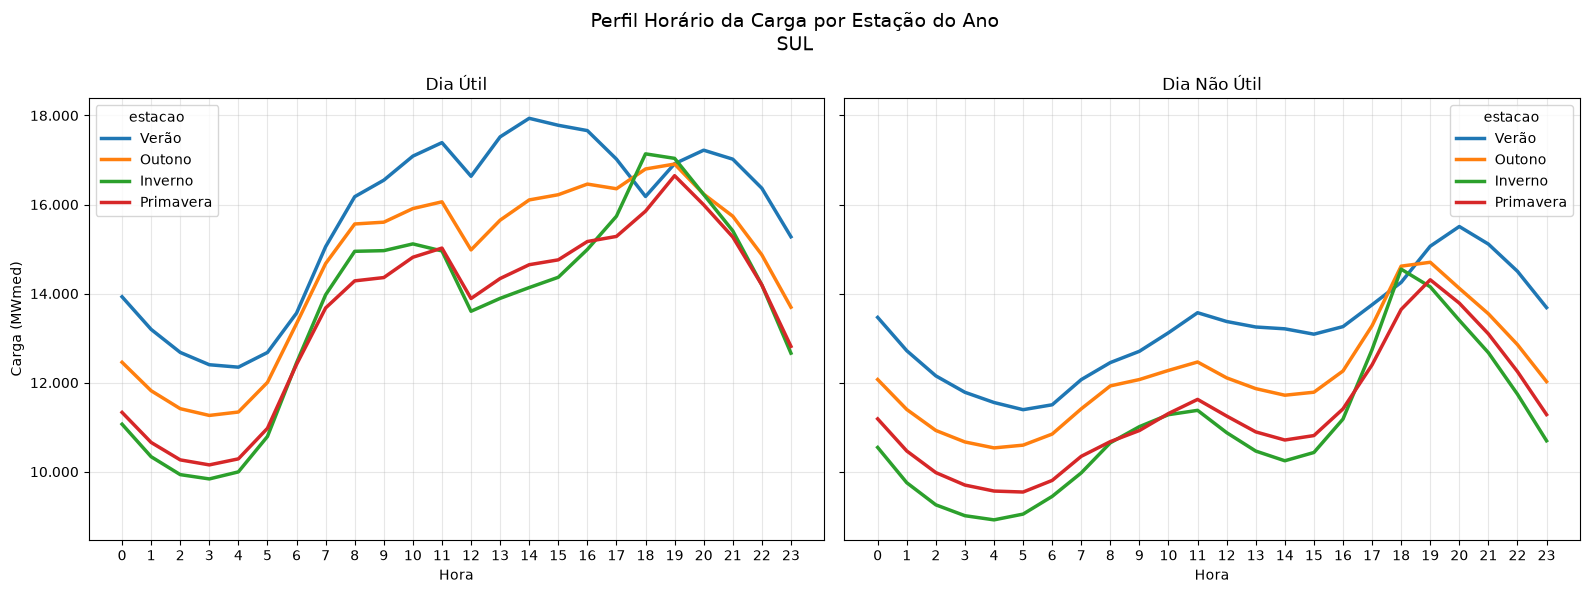

carga_media  carga_maxima  carga_minima
subsistema           tipo_dia                                             
NORDESTE             Dia Não Útil     12111.69      16468.33       7540.36
                     Dia Útil         13124.70      18156.97       7262.28
NORTE                Dia Não Útil      7452.46       9814.43       4966.85
                     Dia Útil          7879.11      10239.23       1364.25
SUDESTE/CENTRO-OESTE Dia Não Útil     39998.35      55040.77      26260.22
                     Dia Útil         44929.90      62149.88      28759.15
SUL                  Dia Não Útil     11487.13      18437.81       6439.20
                     Dia Útil         14033.43      22737.44       7512.66

In [12]:
dados_estacoes = dados.copy()

def definir_estacao(data):

    mes = data.month

    if mes in [12, 1, 2]:
        return "Verão"

    elif mes in [3, 4, 5]:
        return "Outono"

    elif mes in [6, 7, 8]:
        return "Inverno"

    else:
        return "Primavera"

dados_estacoes["estacao"] = (
    dados_estacoes["data_hora"]
    .apply(definir_estacao)
)

dados_estacoes = dados_estacoes[
    (
        (dados_estacoes["ano"] == 2025)
        &
        (dados_estacoes["mes"] != 12)
    )
    |
    (
        (dados_estacoes["ano"] == 2024)
        &
        (dados_estacoes["mes"] == 12)
    )
]
# ==================================================

perfil_estacao = (
    dados_estacoes
    .query("cod_sub != 'SIN'")
    .groupby(
        [
            "subsistema",
            "tipo_dia",
            "estacao",
            "hora"
        ]
    )["carga"]
    .mean()
    .reset_index()
)

ordem = [
    "Verão",
    "Outono",
    "Inverno",
    "Primavera"
]

for sub in perfil_estacao["subsistema"].unique():

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16,6),
        sharey=True
    )

    for i, tipo in enumerate(
        ["Dia Útil", "Dia Não Útil"]
    ):

        dados_plot = perfil_estacao[
            (perfil_estacao["subsistema"] == sub)
            &
            (perfil_estacao["tipo_dia"] == tipo)
        ]

        sns.lineplot(
            data=dados_plot,
            x="hora",
            y="carga",
            hue="estacao",
            hue_order=ordem,
            linewidth=2.5,
            ax=axes[i]
        )

        axes[i].set_title(tipo)

        axes[i].set_xlabel("Hora")

        axes[i].set_ylabel("Carga (MWmed)")

        axes[i].set_xticks(range(24))

        axes[i].grid(alpha=0.3)

        axes[i].yaxis.set_major_formatter(
            FuncFormatter(
                lambda x, p:
                f"{x:,.0f}".replace(",", ".")
            )
        )

    fig.suptitle(
        f"Perfil Horário da Carga por Estação do Ano\n{sub}",
        fontsize=14
    )

    plt.tight_layout()
    nome_sub = (
        sub
        .replace("/", "_")
        .replace(" ", "_")
    )
    plt.savefig(
       PASTA_SAIDA / f"Perfil_hora_estacao_{nome_sub}.png",
       dpi=300,
       bbox_inches="tight"
    )
    plt.show()
    resumo_tipo_dia = (
    dados
    .query("cod_sub != 'SIN'")
    .groupby(
        ["subsistema", "tipo_dia"]
    )
    .agg(
        carga_media=("carga","mean"),
        carga_maxima=("carga","max"),
        carga_minima=("carga","min")
    )
    .round(2)
)

display(resumo_tipo_dia)

## 10. Participação nos intercambios

In [13]:
imp_exp = (
    dados_2025
    .query("cod_sub != 'SIN'")
    .groupby("subsistema")["condicao"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("percentual")
    .reset_index()
)

display(imp_exp)
imp_exp.to_csv(
    PASTA_SAIDA / "02_percentual_importacao_exportacao.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
    index=False
)

,subsistema,condicao,percentual
0,NORDESTE,Exportador,92.92
1,NORDESTE,Importador,7.08
2,NORTE,Exportador,55.16
3,NORTE,Importador,44.84
4,SUDESTE/CENTRO-OESTE,Importador,96.32
5,SUDESTE/CENTRO-OESTE,Exportador,3.68
6,SUL,Importador,73.55
7,SUL,Exportador,26.45


## 11. Definição da zona favoravel para limitações nos intercambios usando boxplot


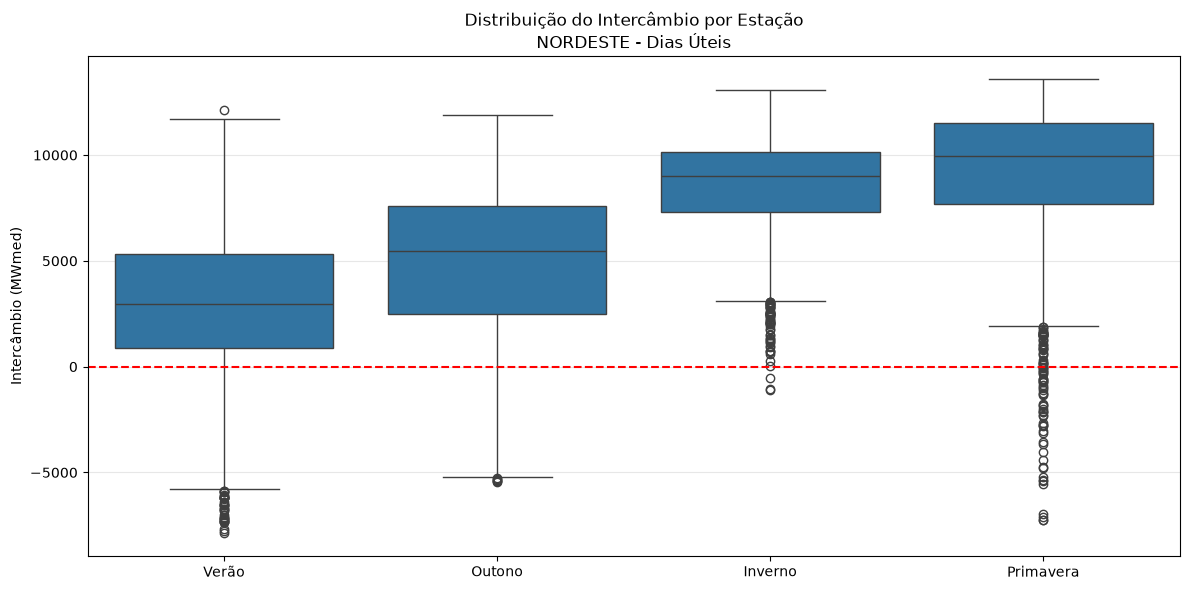

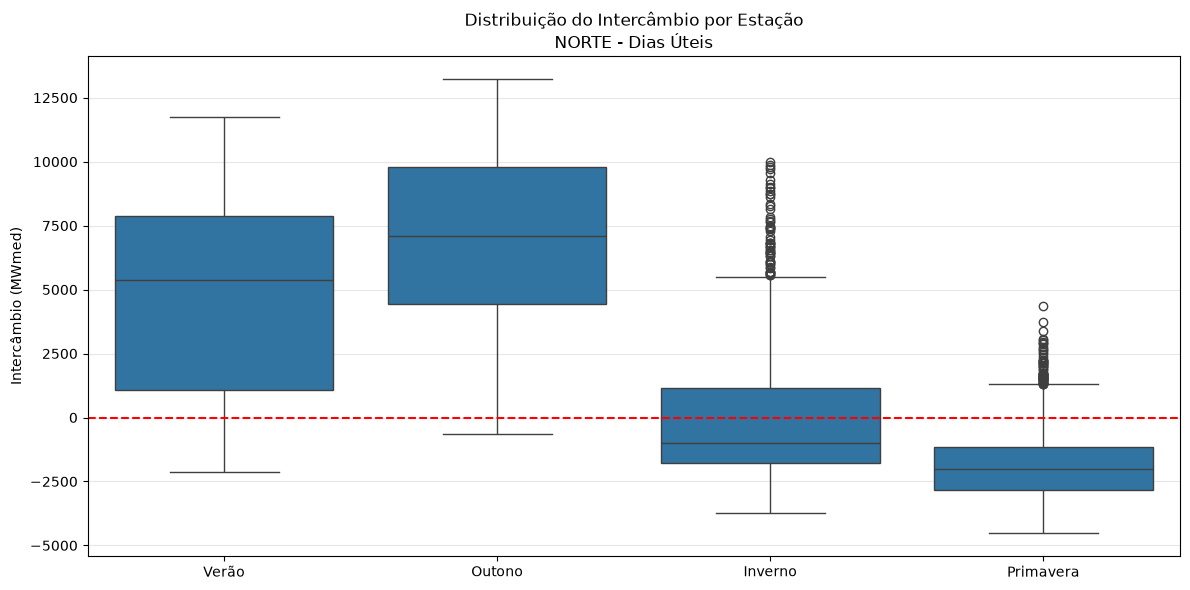

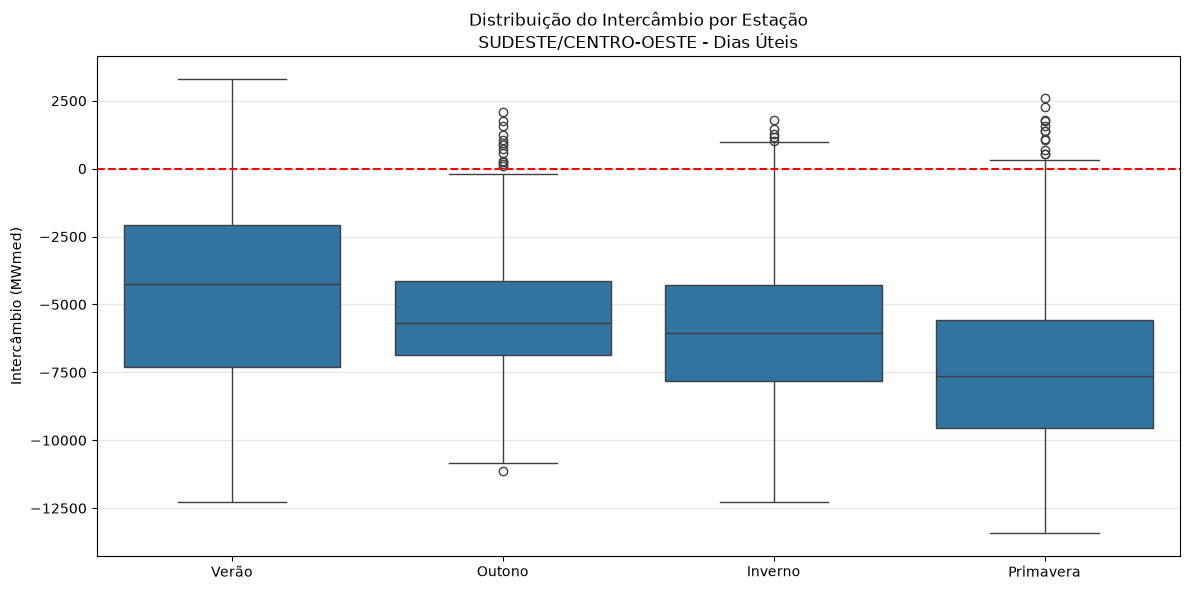

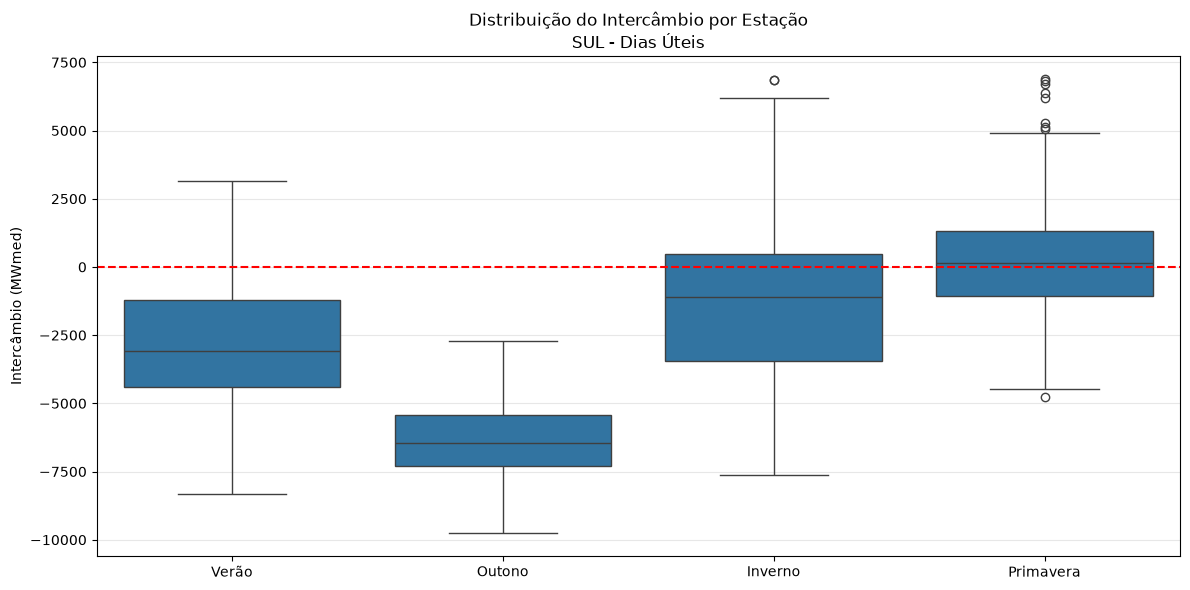

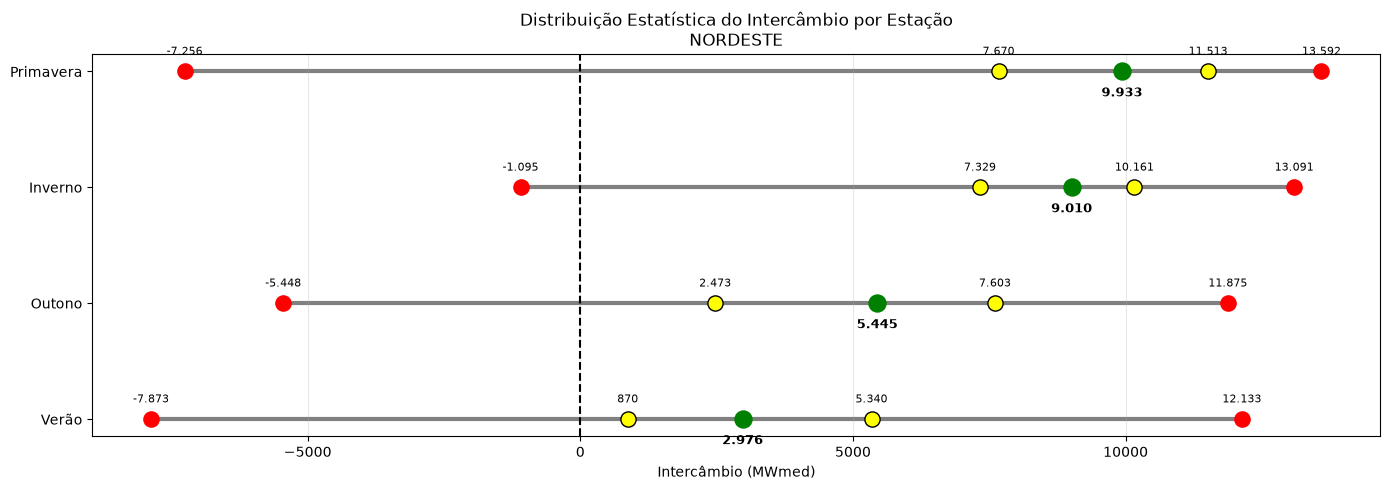

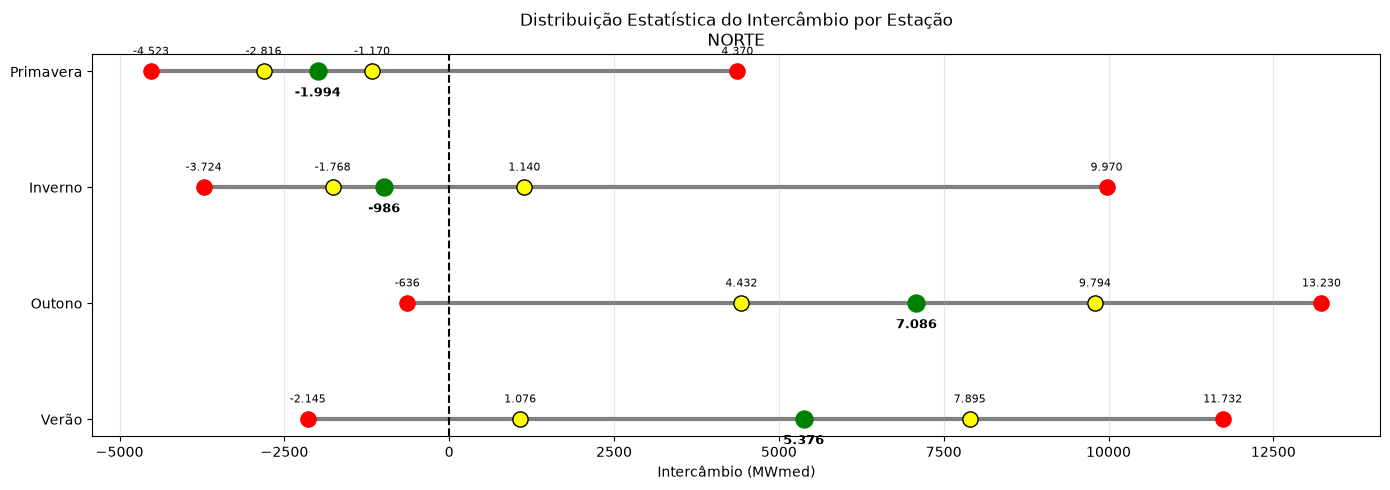

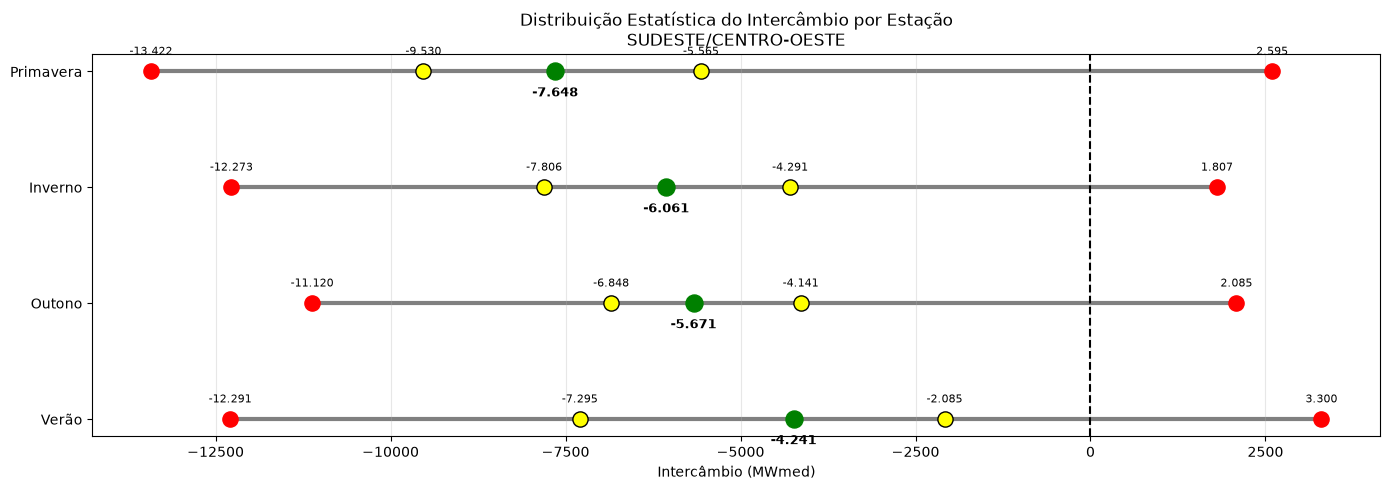

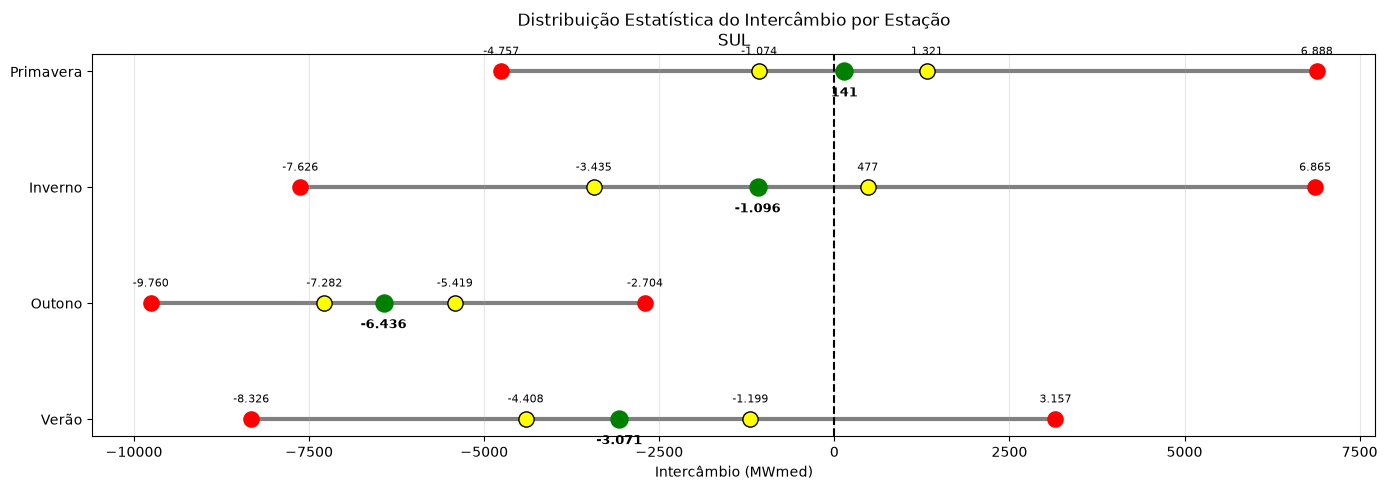

In [14]:
dados_estacoes = dados.copy()

def definir_estacao(data):

    mes = data.month

    if mes in [12, 1, 2]:
        return "Verão"

    elif mes in [3, 4, 5]:
        return "Outono"

    elif mes in [6, 7, 8]:
        return "Inverno"

    else:
        return "Primavera"

dados_estacoes["estacao"] = (
    dados_estacoes["data_hora"]
    .apply(definir_estacao)
)

# Mantém apenas as estações completas do ciclo 2025

dados_estacoes = dados_estacoes[
    (
        (dados_estacoes["ano"] == 2025)
        &
        (dados_estacoes["mes"] != 12)
    )
    |
    (
        (dados_estacoes["ano"] == 2024)
        &
        (dados_estacoes["mes"] == 12)
    )
].copy()

dados_estacoes_util = dados_estacoes.query(
    "cod_sub != 'SIN' and tipo_dia == 'Dia Útil'"
).copy()

ordem_estacoes = [
    "Verão",
    "Outono",
    "Inverno",
    "Primavera"
]

for sub in dados_estacoes_util["subsistema"].unique():

    plt.figure(figsize=(12,6))

    sns.boxplot(
        data=dados_estacoes_util[
            dados_estacoes_util["subsistema"] == sub
        ],
        x="estacao",
        y="intercambio",
        order=ordem_estacoes
    )

    plt.axhline(
        0,
        color="red",
        linestyle="--",
        linewidth=1.5
    )

    plt.title(
        f"Distribuição do Intercâmbio por Estação\n{sub} - Dias Úteis"
    )

    plt.xlabel("")
    plt.ylabel("Intercâmbio (MWmed)")

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    nome_sub = (
        sub
        .replace("/", "_")
        .replace(" ", "_")
    )
    plt.savefig(
       PASTA_SAIDA / f"Boxplot_{nome_sub}.png",
       dpi=300,
       bbox_inches="tight"
    )

    plt.show()

ordem_estacoes = [
    "Verão",
    "Outono",
    "Inverno",
    "Primavera"
]

tabela_boxplot = (
    dados_estacoes_util
    .groupby(
        ["subsistema", "estacao"]
    )["intercambio"]
    .describe()
    [
        [
            "min",
            "25%",
            "50%",
            "75%",
            "max"
        ]
    ]
    .reindex(ordem_estacoes, level="estacao")
    .round(0)
)

display(
    tabela_boxplot.style.format(
        lambda x: f"{x:,.0f}".replace(",", ".")
    )
)

tabela_boxplot.to_csv(
    PASTA_SAIDA / "03_percentis_intercambio_estacoes.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig"
)

ordem_estacoes = [
    "Verão",
    "Outono",
    "Inverno",
    "Primavera"
]

estat = (
    dados_estacoes_util
    .groupby(
        ["subsistema", "estacao"]
    )["intercambio"]
    .describe()
    [
        [
            "min",
            "25%",
            "50%",
            "75%",
            "max"
        ]
    ]
    .reset_index()
)

for sub in estat["subsistema"].unique():

    dados_sub = (
        estat[
            estat["subsistema"] == sub
        ]
        .set_index("estacao")
        .reindex(ordem_estacoes)
        .reset_index()
    )

    plt.figure(figsize=(14,5))

    for y, linha in enumerate(dados_sub.index):

        valor_min = dados_sub.loc[linha, "min"]
        valor_q1 = dados_sub.loc[linha, "25%"]
        valor_med = dados_sub.loc[linha, "50%"]
        valor_q3 = dados_sub.loc[linha, "75%"]
        valor_max = dados_sub.loc[linha, "max"]

        # Linha principal
        plt.plot(
            [valor_min, valor_max],
            [y, y],
            color="gray",
            linewidth=3,
            zorder=1
        )

        # Mínimo
        plt.scatter(
            valor_min,
            y,
            color="red",
            s=120,
            zorder=3
        )

        plt.annotate(
            f"{valor_min:,.0f}".replace(",", "."),
            (valor_min, y),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

        # P25
        plt.scatter(
            valor_q1,
            y,
            color="yellow",
            edgecolors="black",
            s=120,
            zorder=3
        )

        plt.annotate(
            f"{valor_q1:,.0f}".replace(",", "."),
            (valor_q1, y),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

        # Mediana
        plt.scatter(
            valor_med,
            y,
            color="green",
            s=150,
            zorder=4
        )

        plt.annotate(
            f"{valor_med:,.0f}".replace(",", "."),
            (valor_med, y),
            xytext=(0, -18),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            fontweight="bold"
        )

        # P75
        plt.scatter(
            valor_q3,
            y,
            color="yellow",
            edgecolors="black",
            s=120,
            zorder=3
        )

        plt.annotate(
            f"{valor_q3:,.0f}".replace(",", "."),
            (valor_q3, y),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

        # Máximo
        plt.scatter(
            valor_max,
            y,
            color="red",
            s=120,
            zorder=3
        )

        plt.annotate(
            f"{valor_max:,.0f}".replace(",", "."),
            (valor_max, y),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

    plt.yticks(
        range(len(ordem_estacoes)),
        ordem_estacoes
    )

    plt.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1.5
    )

    plt.title(
        f"Distribuição Estatística do Intercâmbio por Estação\n{sub}"
    )

    plt.xlabel("Intercâmbio (MWmed)")
    plt.ylabel("")

    plt.grid(
        axis="x",
        alpha=0.3
    )

    plt.tight_layout()
    nome_sub = (
        sub
        .replace("/", "_")
        .replace(" ", "_")
    )
    plt.savefig(
       PASTA_SAIDA / f"Valores_favoraveis_intercambio_{nome_sub}.png",
       dpi=300,
       bbox_inches="tight"
    )
    plt.show()

## 12. Carga versus intercambio


Text(0.5, 1.02, 'Carga versus Intercâmbio')

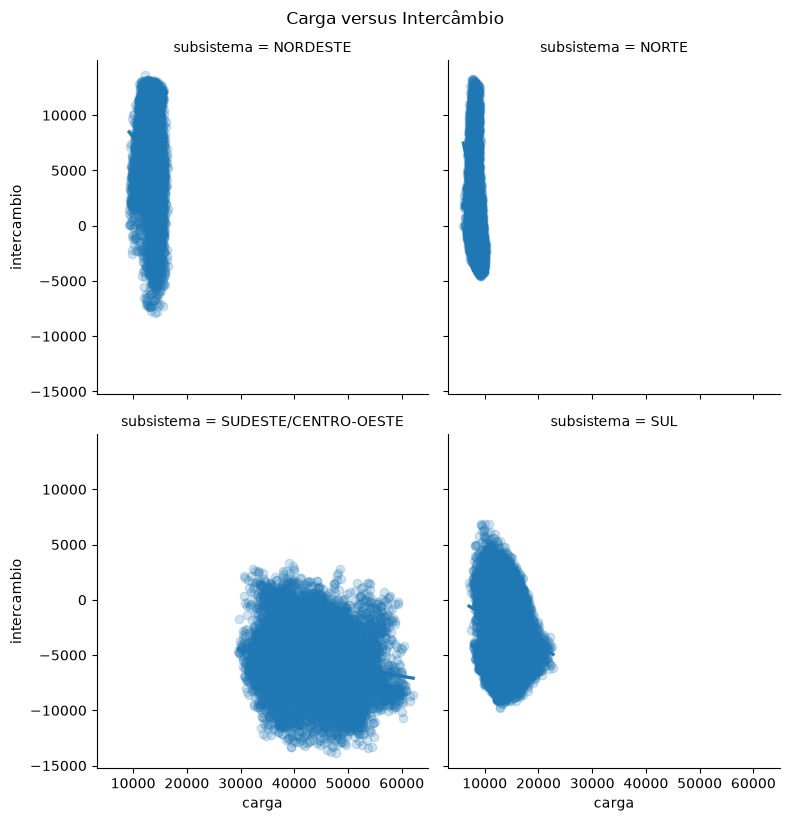

In [15]:
g = sns.lmplot(
    data=dados_2025.query("cod_sub != 'SIN'"),
    x="carga",
    y="intercambio",
    col="subsistema",
    col_wrap=2,
    scatter_kws={"alpha":0.2},
    height=4
)

g.fig.suptitle(
    "Carga versus Intercâmbio",
    y=1.02
)

## Verificação da impressão de arquivos

In [16]:
print("=" * 60)
print("EXPORTAÇÃO CONCLUÍDA")
print("=" * 60)

arquivos = list(PASTA_SAIDA.glob("*"))

for arq in sorted(arquivos):
    print(arq.name)

print()
print(f"Total de arquivos: {len(arquivos)}")

EXPORTAÇÃO CONCLUÍDA
01_estatisticas_gerais_subsistemas.csv
02_percentual_importacao_exportacao.csv
03_percentis_intercambio_estacoes.csv
04_percentis_intercambio_estacoes.csv
Boxplot_NORDESTE.png
Boxplot_NORTE.png
Boxplot_SUDESTE_CENTRO-OESTE.png
Boxplot_SUL.png
Carga_Mensal_NORDESTE.png
Carga_Mensal_NORTE.png
Carga_Mensal_SUDESTE_CENTRO-OESTE.png
Carga_Mensal_SUL.png
Perfil_Mes_NORDESTE.png
Perfil_Mes_NORTE.png
Perfil_Mes_SUDESTE_CENTRO-OESTE.png
Perfil_Mes_SUL.png
Perfil_hora_estacao_NORDESTE.png
Perfil_hora_estacao_NORTE.png
Perfil_hora_estacao_SUDESTE_CENTRO-OESTE.png
Perfil_hora_estacao_SUL.png
Perfil_horario_NORDESTE.png
Perfil_horario_NORTE.png
Perfil_horario_SUDESTE_CENTRO-OESTE.png
Perfil_horario_SUL.png
Valores_favoraveis_intercambio_NORDESTE.png
Valores_favoraveis_intercambio_NORTE.png
Valores_favoraveis_intercambio_SUDESTE_CENTRO-OESTE.png
Valores_favoraveis_intercambio_SUL.png

Total de arquivos: 28
